<a href="https://colab.research.google.com/github/HittersLab/jubilee-trp3-metocean-fatigue-analysis/blob/main/02_Extreme_Value_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Question 1: Generalised Extreme Value (GEV) Distribution and Block Maxima

### Objective
Apply the Block Maxima Method to the significant wave height (`Hs`) dataset and investigate the suitability of the Generalised Extreme Value (GEV) distribution for modelling extreme wave conditions.

### Methodology

1. Load and inspect the original metocean dataset.
2. Convert the timestamp column into a datetime format.
3. Extract the maximum significant wave height for each month.
4. Extract the maximum significant wave height for each year.
5. Fit a GEV distribution to the monthly block maxima.
6. Visualise the monthly maxima and fitted GEV distribution.

### Engineering Consideration

The dataset contains one year of synthetic hourly observations. Consequently, it provides only 12 monthly maxima and one annual maximum. The monthly GEV fit is therefore exploratory, while an annual GEV fit cannot be meaningfully estimated from a single annual observation.

These results are intended for statistical learning and demonstration, not offshore structural design or operational decisions.

Saving jubilee_trp3_synthetic_metocean_1year.csv to jubilee_trp3_synthetic_metocean_1year.csv
MONTHLY BLOCK MAXIMA
timestamp
2025-01-31    1.862
2025-02-28    3.546
2025-03-31    3.499
2025-04-30    2.188
2025-05-31    3.803
2025-06-30    3.865
2025-07-31    3.936
2025-08-31    3.682
2025-09-30    3.644
2025-10-31    3.548
2025-11-30    3.372
2025-12-31    2.749
Freq: ME, Name: hs_m, dtype: float64

ANNUAL BLOCK MAXIMA
timestamp
2025-12-31    3.936
Freq: YE-DEC, Name: hs_m, dtype: float64

Number of monthly maxima: 12
Number of annual maxima: 1

GEV DISTRIBUTION PARAMETERS
Shape parameter: 1.0531
Location parameter: 3.3860
Scale parameter: 0.5792


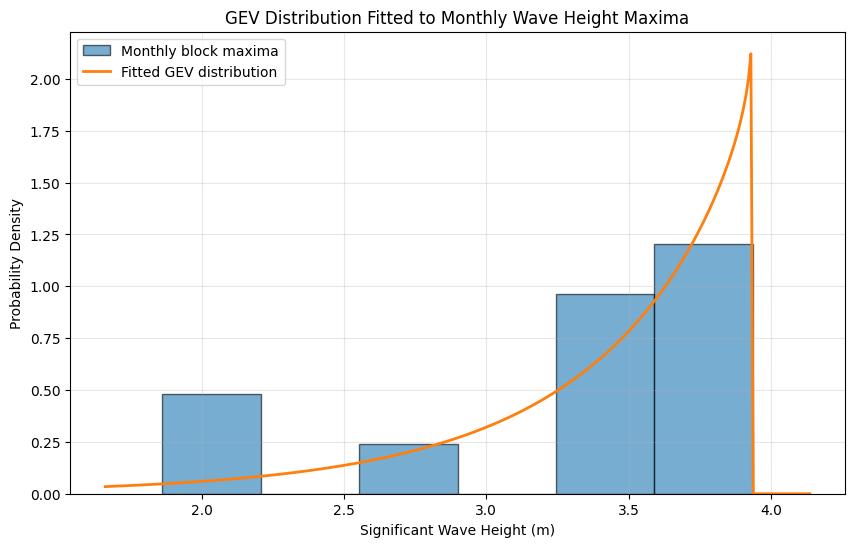


Annual GEV fitting was not performed because there are insufficient annual maxima.


In [ ]:

# QUESTION 1: GEV DISTRIBUTION AND BLOCK MAXIMA

# 1. Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import genextreme

# 2. Upload the original metocean dataset
from google.colab import files

uploaded = files.upload()

# 3. Read the uploaded CSV file
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

# 4. Convert timestamp into datetime format
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 5. Rename Hs_m to hs_m for consistency
if 'Hs_m' in df.columns:
    df.rename(columns={'Hs_m': 'hs_m'}, inplace=True)

# 6. Check that required columns exist
if 'hs_m' not in df.columns:
    raise ValueError("Significant wave height column is missing.")

# 7. Remove missing or invalid observations
df = df.dropna(subset=['timestamp', 'hs_m'])
df = df[df['hs_m'] >= 0].copy()

# 8. Sort observations by timestamp
df = df.sort_values('timestamp')

# 9. Calculate monthly block maxima
monthly_maxima = (
    df.set_index('timestamp')['hs_m']
    .resample('ME')
    .max()
    .dropna()
)

# 10. Calculate annual block maxima
annual_maxima = (
    df.set_index('timestamp')['hs_m']
    .resample('YE')
    .max()
    .dropna()
)

# 11. Display monthly and annual maxima
print("MONTHLY BLOCK MAXIMA")
print(monthly_maxima)

print("\nANNUAL BLOCK MAXIMA")
print(annual_maxima)

print("\nNumber of monthly maxima:", len(monthly_maxima))
print("Number of annual maxima:", len(annual_maxima))

# 12. Fit GEV distribution to monthly maxima
gev_shape, gev_location, gev_scale = genextreme.fit(
    monthly_maxima.values
)

print("\nGEV DISTRIBUTION PARAMETERS")
print(f"Shape parameter: {gev_shape:.4f}")
print(f"Location parameter: {gev_location:.4f}")
print(f"Scale parameter: {gev_scale:.4f}")

# 13. Generate fitted GEV probability density
x = np.linspace(
    monthly_maxima.min() - 0.2,
    monthly_maxima.max() + 0.2,
    300
)

gev_pdf = genextreme.pdf(
    x,
    gev_shape,
    loc=gev_location,
    scale=gev_scale
)

# 14. Plot monthly maxima and fitted GEV distribution
plt.figure(figsize=(10, 6))

plt.hist(
    monthly_maxima.values,
    bins=6,
    density=True,
    alpha=0.6,
    edgecolor='black',
    label='Monthly block maxima'
)

plt.plot(
    x,
    gev_pdf,
    linewidth=2,
    label='Fitted GEV distribution'
)

plt.xlabel('Significant Wave Height (m)')
plt.ylabel('Probability Density')
plt.title('GEV Distribution Fitted to Monthly Wave Height Maxima')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 15. Explain annual GEV limitation
if len(annual_maxima) < 3:
    print(
        "\nAnnual GEV fitting was not performed because "
        "there are insufficient annual maxima."
    )



### Results and Interpretation

The Block Maxima Method was applied to the synthetic Jubilee TRP3 metocean dataset to extract monthly and annual maximum significant wave heights.

A total of 12 monthly maxima and one annual maximum were obtained. The highest monthly significant wave height was 3.936 m, recorded in July 2025. This was also the annual maximum for the dataset.

The Generalised Extreme Value distribution was fitted to the 12 monthly maxima. The estimated parameters were:

- Shape parameter: 1.0531
- Location parameter: 3.3860
- Scale parameter: 0.5792

The fitted GEV distribution provides an exploratory representation of the monthly extreme wave-height observations.

However, the limited sample size introduces considerable uncertainty. In particular, only one annual maximum is available, making annual GEV estimation inappropriate. A longer historical metocean dataset would be required for more reliable extreme wave-height and return-period estimates.

The results demonstrate how block maxima and GEV modelling can be applied in offshore metocean analysis.


## Question 2: Peaks Over Threshold (POT) and Mean Residual Life Analysis

### Objective

Apply the Peaks Over Threshold (POT) method to identify extreme significant wave height observations and investigate a suitable threshold using Mean Residual Life (MRL) analysis.

### Methodology

1. Load and inspect the significant wave height data.
2. Calculate a range of candidate thresholds using selected percentiles.
3. Calculate the mean excess above each threshold.
4. Plot the Mean Residual Life curve.
5. Examine the plot to identify a suitable threshold for subsequent Generalised Pareto Distribution (GPD) modelling.

### Engineering Consideration

The POT method uses observations exceeding a selected threshold rather than retaining only one maximum value per block.

The choice of threshold is important. A threshold that is too low may include ordinary sea states, while a threshold that is too high may leave too few observations for reliable statistical modelling.

The dataset contains one year of synthetic hourly observations. Therefore, the analysis is exploratory and should not be used to establish offshore design wave heights or operational limits.

MEAN RESIDUAL LIFE ANALYSIS
 Percentile  Threshold_m  Mean_Excess_m  Number_of_Exceedances
         80        1.655          0.386                   1751
         81        1.669          0.392                   1662
         82        1.684          0.399                   1571
         83        1.699          0.406                   1487
         84        1.715          0.415                   1402
         85        1.728          0.430                   1309
         86        1.744          0.442                   1227
         87        1.763          0.460                   1132
         88        1.783          0.475                   1049
         89        1.805          0.495                    963
         90        1.833          0.516                    874
         91        1.862          0.541                    788
         92        1.897          0.571                    701
         93        1.943          0.603                    614
         94        2.012   

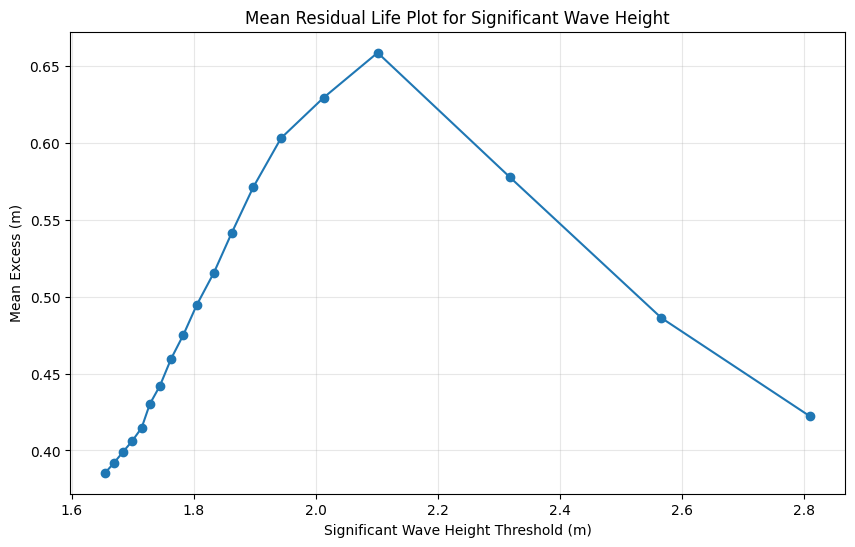

In [ ]:

# QUESTION 2: PEAKS OVER THRESHOLD (POT)
# STEP 1: MEAN RESIDUAL LIFE ANALYSIS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Confirm that the significant wave height column exists
if 'hs_m' not in df.columns and 'Hs_m' in df.columns:
    df.rename(columns={'Hs_m': 'hs_m'}, inplace=True)

# Extract valid significant wave height observations
hs = df['hs_m'].dropna()
hs = hs[hs >= 0]

# Generate candidate thresholds between the 80th and 98th percentiles
percentiles = np.arange(80, 99, 1)

thresholds = np.percentile(hs, percentiles)

# Calculate the mean excess above each threshold
mean_excess = []

for threshold in thresholds:

    # Select observations above the threshold
    exceedances = hs[hs > threshold]

    # Calculate the excess above the threshold
    excess = exceedances - threshold

    # Calculate the mean excess
    mean_excess.append(excess.mean())

# Create a results table
mrl_results = pd.DataFrame({
    'Percentile': percentiles,
    'Threshold_m': thresholds,
    'Mean_Excess_m': mean_excess,
    'Number_of_Exceedances': [
        (hs > threshold).sum() for threshold in thresholds
    ]
})

# Display the results
print("MEAN RESIDUAL LIFE ANALYSIS")
print(mrl_results.round(3).to_string(index=False))

# Plot the Mean Residual Life curve
plt.figure(figsize=(10, 6))

plt.plot(
    thresholds,
    mean_excess,
    marker='o',
    linestyle='-'
)

plt.xlabel('Significant Wave Height Threshold (m)')
plt.ylabel('Mean Excess (m)')
plt.title('Mean Residual Life Plot for Significant Wave Height')

plt.grid(alpha=0.3)
plt.show()


### Threshold Selection and Engineering Interpretation

Based on the Mean Residual Life analysis, the 95th percentile was selected as a provisional threshold for the Peaks Over Threshold analysis.

The selected threshold is approximately 2.101 m, with 438 hourly observations exceeding this value. The mean excess at this threshold is approximately 0.658 m.

The mean excess generally increases between the 80th and 95th percentiles before declining at higher thresholds. This makes the 95th percentile a reasonable candidate for further investigation.

However, threshold selection involves a balance between focusing on extreme wave conditions and retaining sufficient observations for statistical modelling.

The selected threshold will be used to fit a Generalised Pareto Distribution (GPD). Further validation, including consideration of storm-event dependence, is required before interpreting the fitted model as a reliable representation of independent extreme events.

GENERALIZED PARETO DISTRIBUTION RESULTS
Selected threshold: 2.1011 m
Number of exceedances: 438
Shape parameter: -0.5444
Location parameter: 0.0000
Scale parameter: 1.0132 m


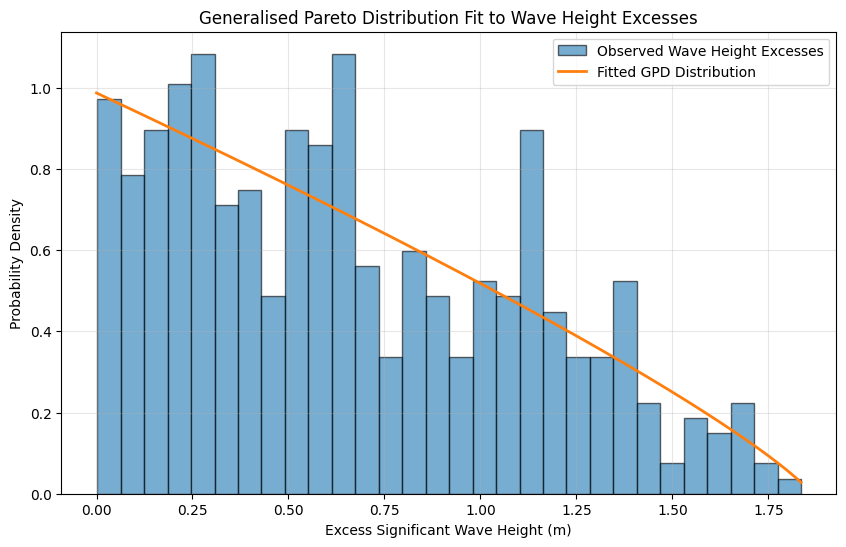

In [ ]:

# QUESTION 2: GENERALIZED PARETO DISTRIBUTION (GPD)

from scipy.stats import genpareto
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Select the 95th percentile threshold
threshold = np.percentile(hs, 95)

# Step 2: Extract observations exceeding the threshold
exceedances = hs[hs > threshold]

# Step 3: Calculate excess wave heights
excess_values = exceedances - threshold

# Step 4: Fit the Generalised Pareto Distribution
gpd_shape, gpd_location, gpd_scale = genpareto.fit(
    excess_values,
    floc=0
)

# Step 5: Display the model results
print("GENERALIZED PARETO DISTRIBUTION RESULTS")

print(f"Selected threshold: {threshold:.4f} m")
print(f"Number of exceedances: {len(exceedances)}")
print(f"Shape parameter: {gpd_shape:.4f}")
print(f"Location parameter: {gpd_location:.4f}")
print(f"Scale parameter: {gpd_scale:.4f} m")

# Step 6: Generate values for the fitted distribution
x = np.linspace(0, excess_values.max(), 300)

gpd_pdf = genpareto.pdf(
    x,
    gpd_shape,
    loc=0,
    scale=gpd_scale
)

# Step 7: Plot the fitted GPD distribution
plt.figure(figsize=(10, 6))

plt.hist(
    excess_values,
    bins=30,
    density=True,
    alpha=0.6,
    edgecolor='black',
    label='Observed Wave Height Excesses'
)

plt.plot(
    x,
    gpd_pdf,
    linewidth=2,
    label='Fitted GPD Distribution'
)

plt.xlabel('Excess Significant Wave Height (m)')
plt.ylabel('Probability Density')
plt.title('Generalised Pareto Distribution Fit to Wave Height Excesses')

plt.legend()
plt.grid(alpha=0.3)
plt.show()


### GPD Results and Interpretation

The Peaks Over Threshold method was applied to the synthetic Jubilee TRP3 metocean dataset using a provisional threshold of 2.1011 m, corresponding to the 95th percentile of significant wave height observations.

A total of 438 hourly observations exceeded the selected threshold.

The Generalised Pareto Distribution was fitted to the resulting excess wave heights, producing the following parameters:

- Shape parameter: -0.5444
- Location parameter: 0.0000
- Scale parameter: 1.0132 m

The negative shape parameter indicates a bounded upper tail under the fitted GPD model. The scale parameter describes the spread of the excess wave-height observations.

The fitted GPD provides an exploratory statistical representation of extreme wave-height exceedances.

However, the hourly observations may exhibit serial dependence because consecutive exceedances can belong to the same storm event. Further analysis involving storm declustering, threshold sensitivity and model validation is therefore required before making reliable extreme-value estimates.

The results are intended for statistical learning and demonstration rather than offshore engineering design or operational decisions.

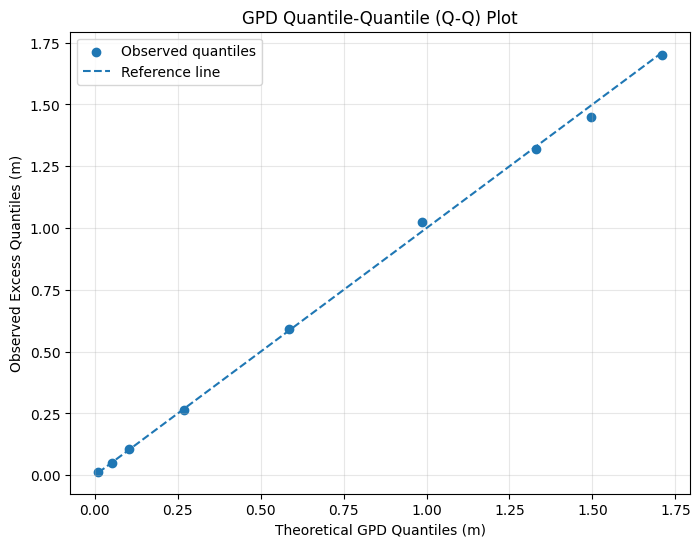

In [ ]:

# QUESTION 2: GPD MODEL VALIDATION USING A Q-Q PLOT

from scipy.stats import genpareto
import matplotlib.pyplot as plt

# Calculate theoretical GPD quantiles
theoretical_quantiles = genpareto.ppf(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99],
    gpd_shape,
    loc=0,
    scale=gpd_scale
)

# Calculate observed excess quantiles
observed_quantiles = excess_values.quantile(
    [0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

# Plot Q-Q comparison
plt.figure(figsize=(8, 6))

plt.scatter(
    theoretical_quantiles,
    observed_quantiles,
    label='Observed quantiles'
)

# Add diagonal reference line
min_value = min(theoretical_quantiles.min(), observed_quantiles.min())
max_value = max(theoretical_quantiles.max(), observed_quantiles.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle='--',
    label='Reference line'
)

plt.xlabel('Theoretical GPD Quantiles (m)')
plt.ylabel('Observed Excess Quantiles (m)')
plt.title('GPD Quantile-Quantile (Q-Q) Plot')

plt.legend()
plt.grid(alpha=0.3)
plt.show()


### GPD Model Validation Using a Q-Q Plot

The fitted Generalised Pareto Distribution was evaluated using a Quantile-Quantile (Q-Q) plot.

The Q-Q plot compares the observed excess wave-height quantiles against the theoretical quantiles predicted by the fitted GPD model.

The plotted points generally follow the diagonal reference line, indicating reasonable agreement between the observed and theoretical distributions.

Small deviations are visible in some of the upper quantiles, suggesting minor differences between the observed and modelled tail behaviour.

Overall, the Q-Q plot provides preliminary visual evidence that the fitted GPD reasonably represents the observed wave-height exceedances at the selected quantiles.

However, this visual assessment does not establish statistical validity. Further analysis, including threshold sensitivity testing and storm declustering, is required before using the model for reliable extreme-wave estimation.

## Question 3: Comparison of GEV and POT Return Levels

### Objective

Compare the return levels estimated using the Generalised Extreme Value (GEV) and Peaks Over Threshold (POT) methods for 1, 10, 50 and 100-year return periods.

### Methodology

1. Use the fitted monthly GEV distribution from Question 1.
2. Use the fitted Generalised Pareto Distribution from Question 2.
3. Calculate return levels for the specified return periods.
4. Present the results in a comparative table.
5. Examine the differences between the two extreme-value modelling approaches.

### Engineering Consideration

The GEV method models block maxima, while the POT method models observations exceeding a selected threshold.

The dataset contains only one year of synthetic hourly observations. Therefore, the monthly GEV and POT return levels are exploratory estimates. An annual GEV model cannot be reliably fitted from only one annual maximum.

Furthermore, the hourly POT exceedances may be serially dependent because multiple exceedances can occur during the same storm event. Storm declustering and additional historical data are required for more reliable return-level estimates.

The comparison is intended for statistical learning and demonstration, not offshore structural design or operational decisions.

GEV AND POT RETURN LEVEL COMPARISON
 Return_Period_years  Monthly_GEV_Return_Level_m  POT_Return_Level_m  Annual_GEV_Return_Level_m
                   1                       3.894               3.894                        NaN
                  10                       3.932               3.943                        NaN
                  50                       3.935               3.954                        NaN
                 100                       3.936               3.956                        NaN

ADDITIONAL MODEL INFORMATION
Observation period: 1.000 years
Hourly exceedance rate: 438.00 per year


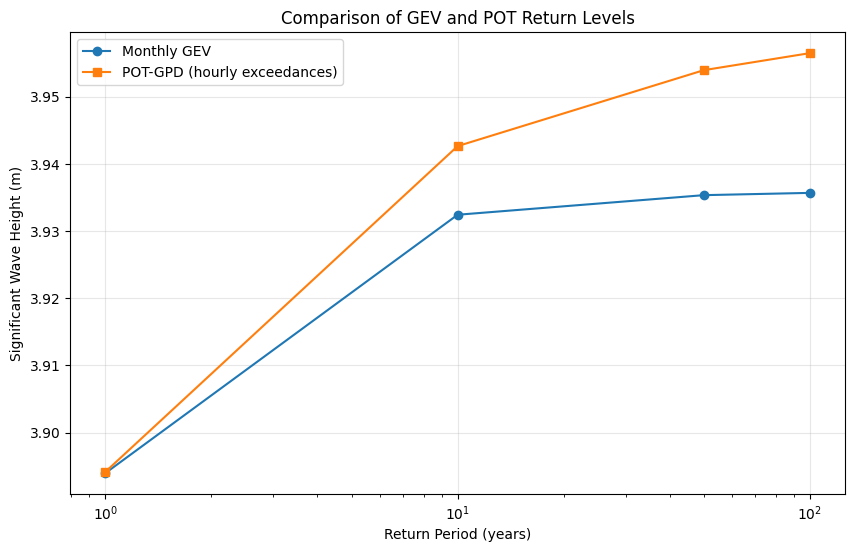

In [ ]:

# QUESTION 3: COMPARISON OF GEV AND POT RETURN LEVELS

import numpy as np
import pandas as pd
from scipy.stats import genextreme, genpareto

# Step 1: Define the required return periods
return_periods = [1, 10, 50, 100]

# Step 2: Estimate the observation period in years
df['timestamp'] = pd.to_datetime(df['timestamp'])

duration_hours = (
    (df['timestamp'].max() - df['timestamp'].min()).total_seconds()
    / 3600
) + 1

exposure_years = duration_hours / 8760

# Step 3: Calculate the hourly POT exceedance rate
exceedance_rate = len(excess_values) / exposure_years

# Step 4: Calculate GEV return levels using monthly maxima
gev_return_levels = []

for T in return_periods:

    # Convert annual return period to monthly block return period
    probability = 1 - (1 / (12 * T))

    return_level = genextreme.ppf(
        probability,
        gev_shape,
        loc=gev_location,
        scale=gev_scale
    )

    gev_return_levels.append(return_level)

# Step 5: Calculate exploratory POT return levels
pot_return_levels = []

for T in return_periods:

    # Approximate exceedance probability for the GPD excess
    probability = 1 - (1 / (exceedance_rate * T))

    excess_return_level = genpareto.ppf(
        probability,
        gpd_shape,
        loc=0,
        scale=gpd_scale
    )

    # Add the threshold to obtain the wave-height return level
    return_level = threshold + excess_return_level

    pot_return_levels.append(return_level)

# Step 6: Create the comparative results table
comparison = pd.DataFrame({
    'Return_Period_years': return_periods,
    'Monthly_GEV_Return_Level_m': gev_return_levels,
    'POT_Return_Level_m': pot_return_levels,
    'Annual_GEV_Return_Level_m': [np.nan] * len(return_periods)
})

# Step 7: Display the results
print("GEV AND POT RETURN LEVEL COMPARISON")
print(comparison.round(3).to_string(index=False))

print("\nADDITIONAL MODEL INFORMATION")
print(f"Observation period: {exposure_years:.3f} years")
print(f"Hourly exceedance rate: {exceedance_rate:.2f} per year")

# Step 8: Plot the comparison
plt.figure(figsize=(10, 6))

plt.plot(
    return_periods,
    gev_return_levels,
    marker='o',
    label='Monthly GEV'
)

plt.plot(
    return_periods,
    pot_return_levels,
    marker='s',
    label='POT-GPD (hourly exceedances)'
)

plt.xscale('log')
plt.xlabel('Return Period (years)')
plt.ylabel('Significant Wave Height (m)')
plt.title('Comparison of GEV and POT Return Levels')

plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Results and Interpretation: GEV and POT Return Level Comparison

The return levels estimated using the monthly GEV and POT-GPD methods were compared for 1, 10, 50 and 100-year return periods.

The monthly GEV estimates were 3.894 m, 3.932 m, 3.935 m and 3.936 m, respectively.

The POT-GPD estimates were 3.894 m, 3.943 m, 3.954 m and 3.956 m, respectively.

The results show that both methods produce relatively similar estimates. The POT estimates are slightly higher than the monthly GEV estimates for the 10, 50 and 100-year return periods.

Both fitted distributions approach finite upper endpoints, which explains why the estimated return levels increase only slightly at longer return periods.

An annual GEV comparison was not performed because the dataset contains only one annual maximum, which is insufficient for reliable annual GEV estimation.

The POT analysis used 438 hourly exceedances over the one-year observation period. However, consecutive exceedances may be associated with the same storm event, meaning that the observations are not necessarily independent.

Overall, the comparison demonstrates the application of two extreme-value analysis techniques to synthetic metocean data. The estimated return levels are exploratory and should not be interpreted as validated offshore design wave heights.

## Question 4: Return Period Plot with Confidence Intervals

### Objective

Develop a return period plot comparing the GEV and POT-GPD return-level estimates, including 95% confidence intervals, and compare the estimated values with the regional reference values provided in the course material.

### Methodology

1. Calculate return levels for 1, 10, 50 and 100-year return periods.
2. Apply bootstrap resampling to estimate uncertainty in the fitted GEV and GPD models.
3. Calculate the 95% confidence intervals.
4. Plot the GEV and POT return-level curves with their confidence intervals.
5. Compare the estimates with the available Gulf of Guinea reference values.

### Engineering Consideration

Confidence intervals provide an indication of uncertainty in estimated extreme wave heights. However, their reliability depends on the quantity and independence of the observations used to fit the statistical models.

The available dataset contains one year of synthetic hourly observations. Therefore, the confidence intervals are exploratory and should not be interpreted as reliable design uncertainty bounds.

The comparison with regional reference values is intended to provide context rather than establish design suitability for the Jubilee TRP3 asset.

SUCCESSFUL BOOTSTRAP SAMPLES
GEV: 500
POT: 500

RETURN LEVELS WITH 95% BOOTSTRAP INTERVALS
 Return_Period_years  GEV_Level_m  GEV_Lower_95_m  GEV_Upper_95_m  POT_Level_m  POT_Lower_95_m  POT_Upper_95_m
                   1        3.894           3.660           3.938        3.894           3.799           3.925
                  10        3.932           3.681           5.020        3.943           3.830           3.979
                  50        3.935           3.682           7.057        3.954           3.837           3.993
                 100        3.936           3.682           8.697        3.956           3.838           3.996


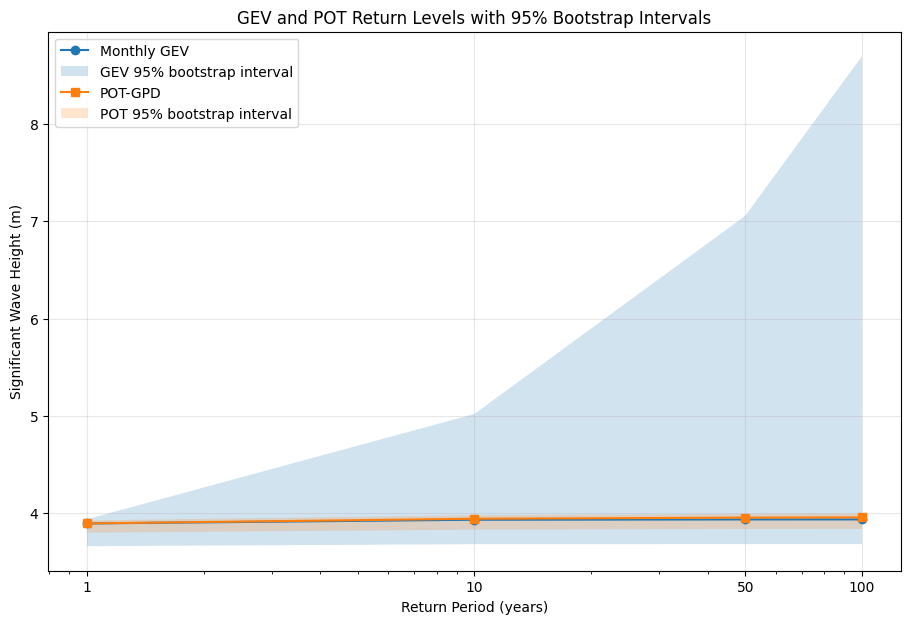

In [ ]:

# QUESTION 4: RETURN PERIOD PLOT WITH 95% CONFIDENCE INTERVALS

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genextreme, genpareto

# Step 1: Define return periods
return_periods = np.array([1, 10, 50, 100])

# Step 2: Set bootstrap iterations
n_bootstrap = 500

# Store bootstrap results
gev_bootstrap = []
pot_bootstrap = []

# Step 3: Bootstrap the monthly GEV model
monthly_data = monthly_maxima.values

for i in range(n_bootstrap):

    sample = np.random.choice(
        monthly_data,
        size=len(monthly_data),
        replace=True
    )

    try:
        c, loc, scale = genextreme.fit(sample)

        if scale <= 0:
            continue

        levels = []

        for T in return_periods:
            probability = 1 - (1 / (12 * T))

            level = genextreme.ppf(
                probability,
                c,
                loc=loc,
                scale=scale
            )

            levels.append(level)

        if np.all(np.isfinite(levels)):
            gev_bootstrap.append(levels)

    except Exception:
        continue

# Step 4: Bootstrap the POT-GPD model
excess_array = np.asarray(excess_values)

for i in range(n_bootstrap):

    sample = np.random.choice(
        excess_array,
        size=len(excess_array),
        replace=True
    )

    try:
        shape, loc, scale = genpareto.fit(
            sample,
            floc=0
        )

        if scale <= 0:
            continue

        levels = []

        for T in return_periods:

            probability = 1 - (
                1 / (exceedance_rate * T)
            )

            level = threshold + genpareto.ppf(
                probability,
                shape,
                loc=0,
                scale=scale
            )

            levels.append(level)

        if np.all(np.isfinite(levels)):
            pot_bootstrap.append(levels)

    except Exception:
        continue

# Step 5: Convert results into arrays
gev_bootstrap = np.asarray(gev_bootstrap)
pot_bootstrap = np.asarray(pot_bootstrap)

print("SUCCESSFUL BOOTSTRAP SAMPLES")
print("GEV:", len(gev_bootstrap))
print("POT:", len(pot_bootstrap))

# Step 6: Calculate 95% confidence intervals
gev_lower = np.percentile(gev_bootstrap, 2.5, axis=0)
gev_upper = np.percentile(gev_bootstrap, 97.5, axis=0)

pot_lower = np.percentile(pot_bootstrap, 2.5, axis=0)
pot_upper = np.percentile(pot_bootstrap, 97.5, axis=0)

# Step 7: Calculate original model return levels
gev_levels = []
pot_levels = []

for T in return_periods:

    probability = 1 - (1 / (12 * T))

    gev_levels.append(
        genextreme.ppf(
            probability,
            gev_shape,
            loc=gev_location,
            scale=gev_scale
        )
    )

    pot_probability = 1 - (
        1 / (exceedance_rate * T)
    )

    pot_levels.append(
        threshold + genpareto.ppf(
            pot_probability,
            gpd_shape,
            loc=0,
            scale=gpd_scale
        )
    )

# Step 8: Display confidence interval table
results = pd.DataFrame({
    'Return_Period_years': return_periods,
    'GEV_Level_m': gev_levels,
    'GEV_Lower_95_m': gev_lower,
    'GEV_Upper_95_m': gev_upper,
    'POT_Level_m': pot_levels,
    'POT_Lower_95_m': pot_lower,
    'POT_Upper_95_m': pot_upper
})

print("\nRETURN LEVELS WITH 95% BOOTSTRAP INTERVALS")
print(results.round(3).to_string(index=False))

# Step 9: Plot return levels and confidence intervals
plt.figure(figsize=(11, 7))

plt.plot(
    return_periods,
    gev_levels,
    marker='o',
    label='Monthly GEV'
)

plt.fill_between(
    return_periods,
    gev_lower,
    gev_upper,
    alpha=0.2,
    label='GEV 95% bootstrap interval'
)

plt.plot(
    return_periods,
    pot_levels,
    marker='s',
    label='POT-GPD'
)

plt.fill_between(
    return_periods,
    pot_lower,
    pot_upper,
    alpha=0.2,
    label='POT 95% bootstrap interval'
)

plt.xscale('log')
plt.xlabel('Return Period (years)')
plt.ylabel('Significant Wave Height (m)')
plt.title('GEV and POT Return Levels with 95% Bootstrap Intervals')

plt.xticks(return_periods, return_periods)
plt.grid(alpha=0.3)
plt.legend()
plt.show()


### Comparison with Table 3.6: Extreme Wave Heights in the Gulf of Guinea

The estimated GEV and POT return levels were compared with the typical Gulf of Guinea extreme significant wave-height ranges provided in Table 3.6.

The comparison produced the following observations:

- **1-year return period:** Both model estimates of 3.894 m exceed the reference range of 2.5–2.8 m.
- **10-year return period:** The GEV estimate of 3.932 m and POT estimate of 3.943 m exceed the reference range of 3.0–3.5 m.
- **50-year return period:** Both estimates are slightly above the reference upper limit of 3.9 m.
- **100-year return period:** Both estimates fall within the reference range of 3.5–4.2 m.

The comparison indicates differences between the model estimates and the regional reference values, particularly at the 1-year and 10-year return periods.

These differences should be interpreted cautiously because the regional values are typical reference ranges, whereas the statistical models were fitted to one year of synthetic hourly metocean observations.

Furthermore, the wide GEV bootstrap confidence intervals at longer return periods indicate substantial extrapolation uncertainty.

The comparison is limited to significant wave height (Hs). The Hmax and associated Tp reference values were not independently modelled in this analysis.

Overall, Table 3.6 provides a useful regional benchmark for evaluating the exploratory GEV and POT results, but it does not establish the accuracy or engineering suitability of the fitted models.

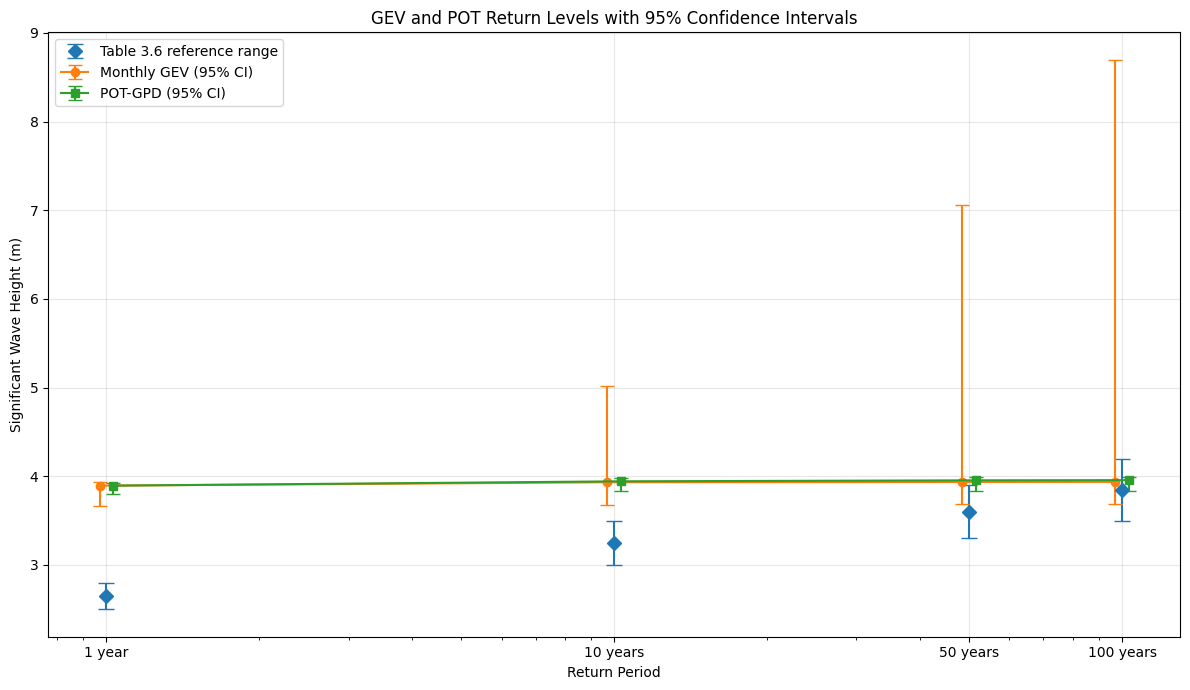

In [ ]:

# QUESTION 4: RETURN PERIOD PLOT WITH 95% CONFIDENCE INTERVALS
# AND TABLE 3.6 COMPARISON

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Step 1: Define return periods
return_periods = np.array([1, 10, 50, 100])

# Step 2: Enter the verified bootstrap results
gev_level = np.array([3.894, 3.932, 3.935, 3.936])
gev_lower = np.array([3.660, 3.681, 3.682, 3.682])
gev_upper = np.array([3.938, 5.020, 7.057, 8.697])

pot_level = np.array([3.894, 3.943, 3.954, 3.956])
pot_lower = np.array([3.799, 3.830, 3.837, 3.838])
pot_upper = np.array([3.925, 3.979, 3.993, 3.996])

# Step 3: Enter Table 3.6 reference ranges for Hs
reference_lower = np.array([2.5, 3.0, 3.3, 3.5])
reference_upper = np.array([2.8, 3.5, 3.9, 4.2])

# Step 4: Calculate asymmetric confidence interval widths
gev_error = np.array([
    gev_level - gev_lower,
    gev_upper - gev_level
])

pot_error = np.array([
    pot_level - pot_lower,
    pot_upper - pot_level
])

# Step 5: Create the return-period plot
plt.figure(figsize=(12, 7))

# Plot Table 3.6 reference ranges
plt.errorbar(
    return_periods,
    (reference_lower + reference_upper) / 2,
    yerr=[
        (reference_upper - reference_lower) / 2,
        (reference_upper - reference_lower) / 2
    ],
    fmt='D',
    capsize=6,
    markersize=7,
    label='Table 3.6 reference range'
)

# Plot GEV estimates and confidence intervals
plt.errorbar(
    return_periods * 0.97,
    gev_level,
    yerr=gev_error,
    fmt='o-',
    capsize=5,
    label='Monthly GEV (95% CI)'
)

# Plot POT estimates and confidence intervals
plt.errorbar(
    return_periods * 1.03,
    pot_level,
    yerr=pot_error,
    fmt='s-',
    capsize=5,
    label='POT-GPD (95% CI)'
)

# Step 6: Format the graph
plt.xscale('log')
plt.xticks(
    return_periods,
    ['1 year', '10 years', '50 years', '100 years']
)

plt.xlabel('Return Period')
plt.ylabel('Significant Wave Height (m)')
plt.title(
    'GEV and POT Return Levels with 95% Confidence Intervals'
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

# Save Question 4 return-level comparison results

comparison_table = pd.DataFrame({
    'Return_Period_years': return_periods,
    'Table_3_6_Hs_Lower_m': reference_lower,
    'Table_3_6_Hs_Upper_m': reference_upper,
    'GEV_Level_m': gev_level,
    'GEV_Lower_95_m': gev_lower,
    'GEV_Upper_95_m': gev_upper,
    'POT_Level_m': pot_level,
    'POT_Lower_95_m': pot_lower,
    'POT_Upper_95_m': pot_upper
})

comparison_table.to_csv(
    'gev_pot_return_level_comparison.csv',
    index=False
)

print("Comparison table saved successfully.")
display(comparison_table.round(3))


Comparison table saved successfully.


,Return_Period_years,Table_3_6_Hs_Lower_m,Table_3_6_Hs_Upper_m,GEV_Level_m,GEV_Lower_95_m,GEV_Upper_95_m,POT_Level_m,POT_Lower_95_m,POT_Upper_95_m
0,1,2.5,2.8,3.894,3.660,3.938,3.894,3.799,3.925
1,10,3.0,3.5,3.932,3.681,5.020,3.943,3.830,3.979
2,50,3.3,3.9,3.935,3.682,7.057,3.954,3.837,3.993
3,100,3.5,4.2,3.936,3.682,8.697,3.956,3.838,3.996


In [ ]:

from google.colab import files

files.download('gev_pot_return_level_comparison.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Interpretation and Engineering Implications

The GEV and POT-GPD methods produced similar significant wave height estimates across the selected return periods. The estimated return levels were approximately 3.894 m for the 1-year return period and increased to approximately 3.936 m and 3.956 m for the 100-year return period using GEV and POT-GPD respectively.

The GEV confidence intervals became substantially wider at longer return periods, indicating considerable uncertainty in the extrapolated estimates. The POT-GPD confidence intervals were narrower, although their reliability depends on the treatment of dependence between consecutive hourly exceedances.

When compared with the regional reference ranges in Table 3.6, some model estimates fall outside the stated ranges. This difference should not be interpreted as proof that the models are inaccurate because the analysis uses only one year of synthetic data rather than long-term measured field observations.

**Engineering limitation:** These return-level estimates are preliminary statistical results. A longer observational record, storm-event declustering, suitable model validation and a dependence-aware uncertainty analysis would be required before using them for subsea engineering design or operational decisions.